# Week 2 — First ML Model: comparing two algorithms
**Task:** predict disease progression one year after baseline from 10 patient measurements (scikit-learn's bundled *Diabetes* dataset, 442 patients; features are mean-centred and scaled by scikit-learn).
**Problem type:** regression. **Algorithms compared:** Linear Regression vs Random Forest Regressor. **Metrics:** MSE and R².

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

X, y = load_diabetes(return_X_y=True, as_frame=True)
print(X.shape, "| target mean %.1f, std %.1f" % (y.mean(), y.std()))
X.head()

(442, 10) | target mean 152.1, std 77.1


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## 1. Train / test split
Always split first: 80% train, 20% test, fixed seed. The test set is only touched for the final score.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)

train: (353, 10)  test: (89, 10)


## 2. Baseline
A model that always predicts the training mean tells us what "no skill" looks like.

In [3]:
baseline_pred = np.full(len(y_test), y_train.mean())
print("Baseline MSE: %.1f | R²: %.3f" % (mean_squared_error(y_test, baseline_pred), r2_score(y_test, baseline_pred)))

Baseline MSE: 5361.5 | R²: -0.012


## 3. Train both models

In [4]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
}
rows, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test); preds[name] = p
    rows.append({
        "model": name,
        "test MSE": mean_squared_error(y_test, p),
        "test RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "test MAE": mean_absolute_error(y_test, p),
        "test R²": r2_score(y_test, p),
        "train R²": r2_score(y_train, m.predict(X_train)),
        "5-fold CV R²": cross_val_score(m, X, y, cv=5, scoring="r2").mean(),
    })
results = pd.DataFrame(rows).set_index("model").round(3)
results

,test MSE,test RMSE,test MAE,test R²,train R²,5-fold CV R²
model,,,,,,
Linear Regression,2900.194,53.853,42.794,0.453,0.528,0.482
Random Forest,2998.341,54.757,44.578,0.434,0.924,0.421


## 4. Visual check: predicted vs actual

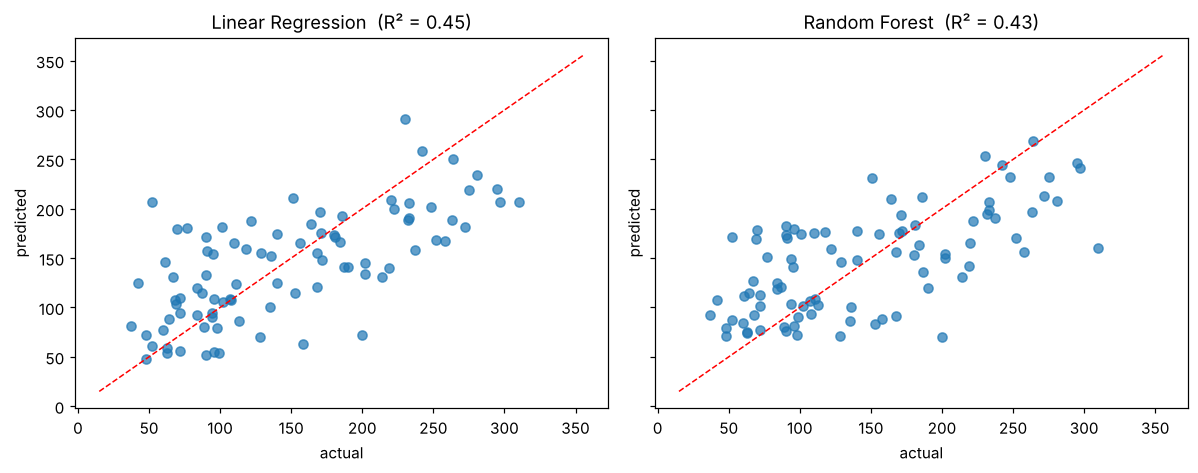

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
lim = [y.min() - 10, y.max() + 10]
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=.7)
    ax.plot(lim, lim, "r--", lw=1)
    ax.set(title=f"{name}  (R² = {r2_score(y_test, p):.2f})", xlabel="actual", ylabel="predicted")
plt.tight_layout(); plt.show()

## 5. What drives the prediction?

,Linear coef,RF importance
bmi,542.429,0.346
s5,736.199,0.245
bp,347.704,0.088
s6,48.671,0.068


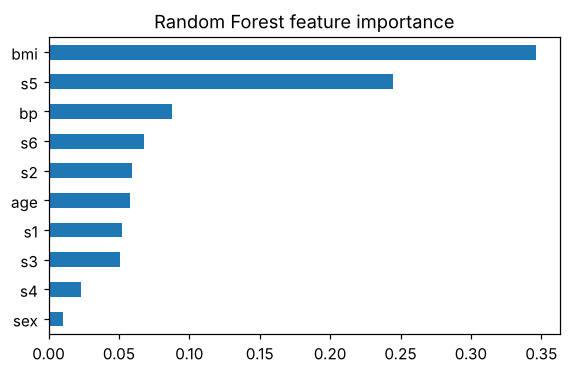

In [6]:
imp = pd.DataFrame({
    "Linear coef": models["Linear Regression"].coef_,
    "RF importance": models["Random Forest"].feature_importances_,
}, index=X.columns).sort_values("RF importance", ascending=False).round(3)
fig, ax = plt.subplots(figsize=(6, 3.5))
imp["RF importance"].plot.barh(ax=ax).invert_yaxis()
ax.set_title("Random Forest feature importance")
plt.show()
imp.head(4)

## 6. Report

| | Linear Regression | Random Forest |
|---|---|---|
| Test MSE | **2900** | 2998 |
| Test R² | **0.453** | 0.434 |
| Train R² | 0.528 | 0.924 |
| 5-fold CV R² | **0.482** | 0.421 |

**Findings**
- Both models beat the mean-only baseline (R² ≈ 0), but the signal is modest: the best model explains about 45% of the variance. RMSE ≈ 54 on a target with std ≈ 77.
- **The simpler model wins.** Linear Regression has slightly lower MSE and higher R² on the test set, and the 5-fold cross-validation agrees, so the result isn't a lucky split.
- **The Random Forest overfits.** It scores R² 0.92 on training data but 0.43 on unseen data — a gap of ~0.5, versus ~0.07 for the linear model. It memorises noise in a dataset of only 442 rows.
- Both agree on the drivers: **BMI** and the blood-serum measure **s5** matter most (RF importance 0.35 and 0.24), followed by blood pressure.

**Lesson:** a more complex model is not automatically better; comparing two models and checking train-vs-test gap tells you more than tuning one model. A next step would be regularising the forest (`max_depth`, `min_samples_leaf`) or trying Ridge regression.